In [12]:
import numpy as np
import itertools
import matplotlib.pyplot as plt

from IPython.display import Video

# Bonus Lecture 1.5: Spin models and variational free energy minimization

* Spin models: exponential families; MCMC for the Ising model, energy and magnetization
* A quick look at optimization: travelling salesman, binary perceptron, simulated annealing
* Variational free energy in physics
* Naive mean field for spin systems
* *Bonus: mean field and Gibbs sampling/Glauber dynamics*

McKay, **Chapter 33**.

*Recommended reading:*
* For a history of more advanced (TAP) mean-field *solutions* to the prototypical spin glass model:
  - [Solvable model of a spin glass](https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.35.1792)
  - [Solution of 'Solvable model of a spin glass'](https://www.tandfonline.com/doi/abs/10.1080/14786437708235992)
  - [Convergence condition of the TAP equation for the infinite-ranged Ising spin glass model](https://iopscience.iop.org/article/10.1088/0305-4470/15/6/035)

## Spin models

### Why should we study a magnetic system in a Machine Learning course?

* **Because**
* Paradigmatic model for the theory of phase transitions
* Close cousin of spin glass models: the physics of such systems is directly related to fundamental problems in neuroscience, machine learning, logic and computer science, e.g.
    - [Hopfield model](https://en.wikipedia.org/wiki/Hopfield_network)
    - [phase transitions in learning and computational problems](https://arxiv.org/abs/cond-mat/0104428)
    - [boolean satisfiability](https://en.wikipedia.org/wiki/Boolean_satisfiability_problem)
  
  and much more

### Exponential families and equilibrium statistical mechanics

The Maximum Entropy principle leads us to consider distributions in the exponential family:
$$
p(x)=\frac{1}{Z}\exp(\psi(x))
$$
Such distributions are ubiquitous both in Machine Learning and Physics [we usually set $\psi(x) = -\beta E(x)$ with $E(x)$ the Hamiltonian/energy function of the system and $\beta =1/\kappa T$ the inverse temperature].

Sampling from these distributions is crucial. On the other hand, optimization wrt a loss function $E(x)$ can be recast as the problem of finding the **ground state** of a system with Hamiltonian $E(x)$.

#### *Bonus: a refresher of basic relations*

The quantity $\log Z$ is useful as a generating functions for the cumulants of quantities of interest, which can be computed with appropriate differentiation. Let us take for example the energy $E$.

We have for the mean energy of the spin system $\langle E \rangle =\sum_x E(x) p(x)$:
$$-\frac{\partial \log Z}{\partial \beta}=-\frac{1}{Z}\frac{\partial Z}{\partial \beta}=\frac{1}{Z}\sum_x E(x) \exp(-\beta E(x))=\langle E \rangle$$

The variance of the energy can be computed similarly:
$$\frac{\partial^2 \log Z}{\partial \beta^2}=\frac{\partial}{\partial \beta} \left(\frac{1}{Z}\frac{\partial Z}{\partial \beta}\right)= -\frac{1}{Z^2} \left(\frac{\partial Z}{\partial \beta}\right)^2 +\frac{1}{Z}\frac{\partial^2 Z}{\partial \beta^2}$$
$$=-\langle E \rangle^2 + \frac{1}{Z}\sum_x E(x)^2\exp(-\beta E(x))=-\langle E \rangle^2+\langle E^2\rangle=\mathbb{V}(E)$$

Note that since $\partial_{T}=-\frac{1}{\kappa T^{2}}\partial_{\beta}$, the so-called **heat capacity** $C=\frac{\partial\left\langle E\right\rangle }{\partial T}$ is directly related to the previous expression, indeed:
$$
C=\frac{\partial\left\langle E\right\rangle }{\partial T}=-\frac{1}{\kappa T^{2}}\partial_{\beta}\left\langle E\right\rangle =\frac{1}{\kappa T^{2}}\partial^2_{\beta}\log Z=\frac{\mathbb{V}\left(E\right)}{\kappa T^{2}}
$$
Note the proportionality constant: large energy fluctuations at high temperatures nevertheless give vanishing heat capacity.

The log partition sum is proportional to the usual free energy in physics $F=-\frac{1}{\beta}\log Z$.

It is trivial to prove that:
$$F=\langle E \rangle-\frac{H}{\beta}\qquad$$
where $H$ is the Shannon entropy of the system:
$$H=-\sum_x p(x) \log p(x)$$

## The Ising model

The Ising model is a probability distribution over vectors of binary variables $x=(x_1,\ldots,x_N)$ with $x_i=\pm 1$:

$$p(x)=\frac{1}{Z}\exp \left(- \beta E(x)\right)\qquad E(x)=-\frac{1}{2}\sum_{i\ne j}J_{ij}x_ix_j-\sum_i h_i x_i$$

$$Z=\sum_x \exp(-\beta E(x))=\sum_{x_1}\ldots \sum_{x_N} \exp(-\beta E(x))$$

where in general $J_{ij}=J_{ji}$ and $J\neq 0$ when $i$ and $j$ are neighbours on a given (undirected) graph, and $0$ otherwise.

(Anti)Ferromagnetic interactions corresponds to ($J_{ij} = -J$) $J_{ij} = +J$.

Note: in what follows, we set $\kappa=1$ for simplicity. More in general, the quantity $\beta$ can be absorbed in the couplings $J_{ij}$.

### Metropolis-Hastings

We will be using proposals distributions where a single (randomly chosen) spin $x_i$ get flipped, namely:
$$
q\left(x'|x\right)=\frac{1}{N}\sum_{i=1}^{N}\prod_{j\neq i}\delta_{x'_{j},x{}_{j}}\delta_{x'_{j},-x{}_{j}}
$$
Each configuration $x$ has non-vanishing probability of jumping onto $N$ possible configurations $x'$ where a single spin has been flipped.

To make things more concrete, we could define the spin-flip operator $F_i$ in such a way that $F_i x$ is the vector of spins obtained by flipping spin $i$. We have:

$$q(F_i x|x)=\frac{1}{N}\qquad q(x|x)=0$$

The MH ratio for the transition from state $x$ to state $F_i x$ is thus

$$a \left(F_i x,x\right)=\frac{p^*(F_ix)}{p^*(x)}=\exp\left(- \beta \Delta E\right)$$

$$\Delta E = E(F_i x)-E(x)=2x_i \sum_{j\ne i} J_{ij}x_j$$

The energy decreases whenever the spin $x_i$ that gets flipped was previoulsy not aligned with its _local field_ $h_i=\sum_{j\ne i} J_{ij}x_j$.

### Gibbs sampling

The conditional probability for spin $i$ to flip only depends on its local field $h_i$ (make sure to do the math yourself!):

$$
p\left(x_{i}|h_{i}\right)=\frac{1}{1+e^{-2\beta x_{i} h_{i}}}
$$

### Measuring autocorrelation

During sampling $x_1,x_2,\ldots,x_N$ one obtains samples of the quantity of interest $Q_t=\phi(x_t)$.
One can estimate the autocorrelation
$$A(\tau) =\frac{\langle Q_tQ_{t+\tau}\rangle-\langle Q_t\rangle^2}{\langle Q_t^2\rangle-\langle Q_t\rangle^2}\propto e^{-\tau/\Theta}$$Note that $A(0)=1$. One expects for ergodic problems that for large $\tau$$$\langle Q_tQ_{t+\tau}\rangle=\langle Q_t\rangle\langle Q_{t+\tau}\rangle=\langle Q_t\rangle^2\qquad \lim_{\tau \to \infty}A(\tau)=0$$

$\Theta$ is the characteristic time on which the samples of the Markov process are correlated.
Thus, the effective number of independent samples is $N/\Theta$ [or better $\frac{N}{1+\Theta}$ to avoid infinities].

#### Visualize samples from a 32x32 2d Ising model at two different temperatures:

In [13]:
# example of an Ising model at T = 10
Video("figs/ising_size32_32_T10.mp4", embed=True)

In [14]:
# example of an Ising model at the critical temperature
Video("figs/ising_size32_32_T2.269.mp4", embed=True)

## Ferro-magnetic Ising model on a square lattice

We consider a square grid of $N=L\times L$ spins with periodic boundary conditions, each coupled to its 4 nearest neighbours with $J_{ij}=1$, and $h_i=0$. The system is run with MH on a temperature cycle (from high to low temperature and back, each chain started from the last sample of the previous one, as a check for equilibrium), with a burn-in of $100N$ steps followed by $S=1000$ samples, one every $100N$ steps.

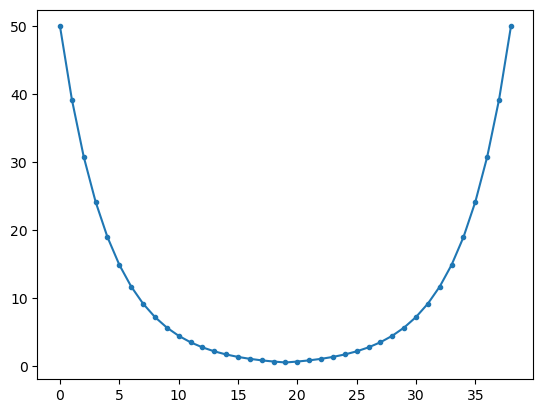

In [15]:
# load results for square grid with 100 spins
res_100 = np.loadtxt("data/ising2d_10_10.dat")

# this is the temperature protocol I used
Ts = res_100[:,0]
plt.plot(Ts, '.-');

### Energy and magnetization

* **Energy** of a configuration: $E(x)=-\sum_{\langle ij\rangle}x_ix_j$, where $\langle ij\rangle$ runs over the $2N$ nearest-neighbour pairs, each counted once. The energy per spin $E/N$ goes from $-2$ (all spins aligned) to $+2$. We measure its mean $\langle E \rangle=\sum_x p(x)E(x)$ and variance $\mathrm{Var}\,E=\langle E^2\rangle-\langle E \rangle^2$.
* **Magnetization** (per spin): $m(x)=\frac{1}{N}\sum_{i} x_i\in[-1,1]$. Since $E(x)=E(-x)$, $\langle m\rangle=0$ in a finite system, so we measure $\langle m^2\rangle$: $\approx 1/N$ at high temperature (nearly independent spins), $\approx 1$ at low temperature (close to one of the two ground states). Its drop marks the phase transition, at $T_c\approx2.269$ for $N\to\infty$.

The averages are estimated from the samples $x^1,\ldots,x^S$ of each chain: $\widehat{\langle E \rangle}=\frac{1}{S}\sum_{s} E(x^s)$, $\widehat{\mathrm{Var}\,E}=\frac{1}{S}\sum_{s} \left(E(x^s) - \widehat{\langle E \rangle}\right)^2$, $\widehat{\langle m^2\rangle} =\frac{1}{S}\sum_{s} m^2(x^s)$. The plots show $\langle E\rangle/N$, with error bars $\sqrt{\mathrm{Var}\,E}/N$, and $\langle m^2\rangle$.

### Mean energy and magnetization

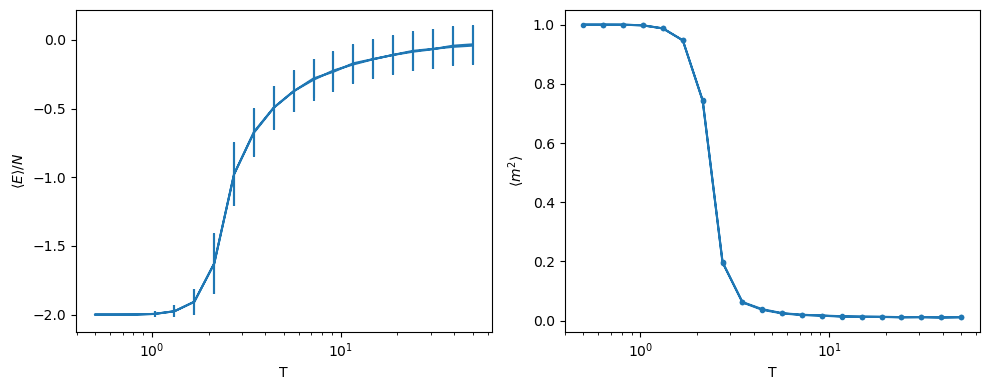

In [16]:
N = 100

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.errorbar(Ts, y=res_100[:,1]/N, yerr=np.sqrt(res_100[:,2])/N)
plt.xscale('log');
plt.xlabel('T')
plt.ylabel(r'$\langle E\rangle/N$')

plt.subplot(122)
plt.plot(Ts, res_100[:,3], '.-')
plt.xscale('log');
plt.xlabel('T')
plt.ylabel(r'$\langle m^2\rangle$')

plt.tight_layout();

## A quick look at optimization

Exponential families connect sampling and optimization: minimizing a cost $E(x)$ means finding the **ground state** of $p(x)\propto e^{-\beta E(x)}$, on which the distribution concentrates as $\beta\to\infty$. Two examples of such energy functions over discrete variables:

* **Travelling salesman problem**: find the shortest tour visiting $n$ cities exactly once. The variables are the tours, i.e. cyclic permutations $\pi$ of the cities, with energy $E(\pi)=\sum_k d_{k\pi(k)}$, $d_{ij}$ the distance between cities $i$ and $j$.
* **Binary perceptron** (a quantized neural network): weights $w_i=\pm1$ and output $y(x)=\text{sign}(w\cdot x)$; on a data set $\{x^\mu,t^\mu\}_{\mu=1}^P$ with $t^\mu=\pm1$, the energy $E(w)=\sum_{\mu}\theta\left(-t^{\mu}w\cdot x^{\mu}\right)$ counts the misclassified examples.

**Simulated annealing** turns optimization into a sequence of sampling problems: run MCMC on $p_k(x)\propto e^{-E(x)/T_k}$ while slowly lowering the temperature $T_k$. Accepting some moves that increase the energy lets it escape the local minima where a greedy search gets stuck; if the temperature is lowered slowly enough, the global minimum is found with probability one (Hajek, 1988).

### An example of Simulated Annealing on a socially relevant travelling salesman problem

Illustration of the solution to the following TSP problem: find the best bike route for a tour of all bars in Nijmegen.

Distances are computed as shortest distances on bike routes on the map.

<center><img src="figs/tsp_nijmegen_map.png"></center>

## Variational approximation and free energy

#### In theory

The mean field approximation is computed by minimizing:

$$\mathrm{KL}(q||p)$$

for a factorized variational distribution $q(x)= \prod_i q_i(x_i)$, more explicitly:
$$\mathrm{KL}(q||p)=\sum_i \sum_{x_i} q_i(x_i) \log q_i(x_i)-\sum_x \prod_i q_i(x_i) \log p(x)$$

Minimization results in a coupled system of mean field equations $\frac{\partial \mathrm{KL}(q||p)}{\partial q_i(x_i)}=0$.

For a physical system (and any model in the exponential family), we can equivalently express the problem with the minimization of an upper bound for the free energy $F$ of the original system, called *variational free energy*. Consider
$$p\left(x\right)=\frac{e^{-\beta E\left(x\right)}}{Z}$$

We have for the KL
$$KL\left(q||p\right)=\sum_{x}q\left(x\right)\log\frac{q\left(x\right)}{e^{-\beta E\left(x\right)}}+\log Z=\beta\left(\tilde{F}-F\right)$$

with the variational free energy $\tilde{F}$ defined by:
$$\beta\tilde{F}=\sum_{x}q\left(x\right)\log\frac{q\left(x\right)}{e^{-\beta E\left(x\right)}}$$

Obviously $\tilde{F}\geq F$ because of non-negativity of the KL.

## Variational approximation and free energy

#### In practice

The resulting equations may have more than one solution (local minima). Parallel updating (fixed point iteration) is faster than sequential updating and usually preferred, but convergence is not guaranteed in this case.

Since KL is equal to the variational free energy up to addition of a constant term, we can equivalently discuss its minimization and convexity. $KL$ is not convex but it is convex in each $q_i$ separately once the others are fixed.

One thus typically uses **coordinate descent**: each term $q_i(x_i)$ is updated sequentially by setting the gradient $\frac{\partial \mathrm{KL}(q||p)}{\partial q_i(x_i)}=0$, while keeping the other terms $\prod_{j\ne i}q_j(x_j)$ fixed. 

In each iteration
$$KL(q_i^\text{new}\prod_{j\ne i} q_j^\text{old}||p)\le KL(q_i^\text{old}\prod_{j\ne i} q_j^\text{old}||p)$$

Therefore, coordinate descent converges to a (local) minimum of $KL(q|p)$.

## The (naive) mean field approximation for spin system

#### Setting

Consider our old friend the spin model $x=(x_1,\ldots,x_N)$ with $x_i=\pm 1$ and
$\sum_{(ij)}=\frac{1}{2}\sum_{i=1}^N\sum_{j=1,j\ne i}^N$ denoting the sum over all pairs.

We have:

$$p(x)=\frac{1}{Z}\exp\left(-\beta E(x)\right)\qquad E(x)=-\sum_{(ij)} J_{ij}x_i x_j -\sum_i h_i x_i\qquad Z=\sum_x \exp\left(-\beta E(x)\right)$$

Assume a factorized variational distribution:
$$q(x)=\prod_{i=1}^N q_i(x_i)$$
We find $q$ by minimizing
$$\mathrm{KL}(q||p)=\sum_x q(x) \log \frac{q(x)}{p(x)}=\sum_x q(x)\log q(x) +\beta \sum_x q(x)E(x) + \log Z$$
$$\langle E \rangle_q=-\sum_{(ij)}J_{ij}\langle x_i x_j \rangle_q-\sum_i h_i \langle x_i \rangle_q=-\sum_{(ij)}J_{ij}m_i m_j-\sum_i h_i m_i$$
with $\langle x_i \rangle_q=m_i$.

## The (naive) mean field approximation for spin system

#### Mean-field equations

We can express $q_i(x_i)$ in terms of $m_i$ as $q_i(x_i)=\frac{1}{2}(1+m_ix_i)$. For the entropy term we have:
$$S=-\sum_x q(x) \log q(x)= -\sum_x q(x)\sum_{i=1}^n \log q_i(x_i)=-\sum_{i=1}^N\sum_{x_i} q_i(x_i) \log q_i(x_i)$$
$$=-\frac{1}{2}\sum_{i=1}^N \left((1+m_i)\log \frac{1}{2}(1+m_i) +(1-m_i)\log \frac{1}{2}(1-m_i)\right)$$

Thus we write:
$$\beta \tilde{F} = \beta \langle E \rangle_q -S = -\sum_{(ij)}J_{ij}m_i m_j-\sum_i h_i m_i$$
$$+\sum_i \frac{1}{2}\left((1+m_i)\log \frac{1}{2}(1+m_i) +(1-m_i)\log \frac{1}{2}(1-m_i)\right)$$We find the minimum by differentiation:
$$\frac{\partial \beta \tilde{F}}{\partial m_i} = \frac{\partial \mathrm{KL}(p||q)}{\partial m_i}= -\sum_{j\ne i} J_{ij}m_j - h_i +\frac{1}{2}\log\frac{1+m_i}{1-m_i}=0$$
It is easy to show that $\frac{1}{2}\log\frac{1+m_i}{1-m_i}=a_i=\tanh^{-1}(m_i)$.
The result in proven once we see that $\tanh\left(\frac{1}{2}\log\frac{1+m}{1-m}\right)=m$.

The mean field equations thus read
$$m_i =\tanh\left(\sum_{j\ne i} J_{ij}m_j +h_i\right)$$

## (Non)convexity of KL / variational free energy

Consider a simple two-sping system with $h_i=0$. The variational free energy thus reads:

$$\beta\tilde{F}=-\beta m_{1}m_{2}-S\left(\frac{1+m_{1}}{2}\right)-S\left(\frac{1+m_{2}}{2}\right)$$

with
$$S\left(p\right)=-p\log p-\left(1-p\right)\log\left(1-p\right)$$

$\beta\tilde{F}$ is not convex in $(m_1,m_2)$. Play around with different values of $\beta$ in the following code:

/tmp/ipykernel_16808/931413770.py:2: RuntimeWarning: divide by zero encountered in log
  return - p * np.log(p) - (1 - p) * np.log(1 - p)
/tmp/ipykernel_16808/931413770.py:2: RuntimeWarning: invalid value encountered in multiply
  return - p * np.log(p) - (1 - p) * np.log(1 - p)


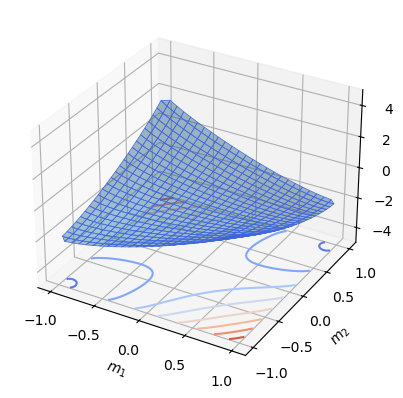

In [17]:
def entropy_bernoulli(p): # NOTE: a less lazy implementation would take care of lim_{p \to 0} S(p) = 0
    return - p * np.log(p) - (1 - p) * np.log(1 - p)

num_m = 200
m_range = np.linspace(-1.,1.,num_m)
M1, M2 = np.meshgrid(m_range, m_range)
p1, p2 = 0.5 * (1 + M1), 0.5 * (1 + M2)

beta = 2.

BFtilde = -beta * M1 * M2 - entropy_bernoulli(p1) - entropy_bernoulli(p2)

ax = plt.figure().add_subplot(projection='3d')
ax.plot_surface(M1, M2, BFtilde, edgecolor='royalblue', lw=0.5, rstride=8, cstride=8, alpha=0.4)
ax.contour(M1, M2, BFtilde, zdir='z', offset=-5, cmap='coolwarm')
ax.set(zlim=(-5, 5))
ax.set_xlabel('$m_1$')
ax.set_ylabel('$m_2$')
plt.show()

$\beta\tilde{F}$ is convex in $m_1$ for fixed $m_2$ and visa versa (note the symmetry between $m_1$ and $m_2$):

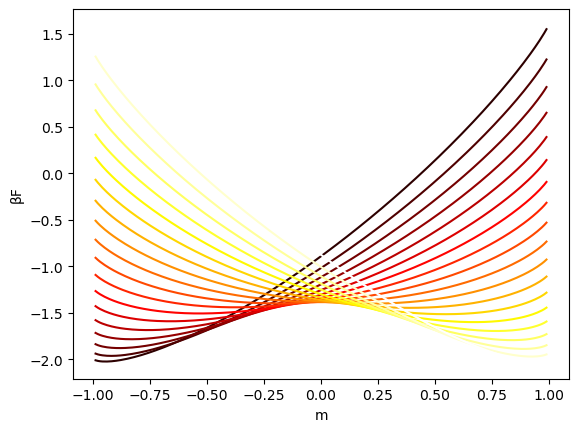

In [18]:
im_to_show = np.arange(0, num_m, 10)
colors = plt.cm.hot(np.linspace(0, 1, len(im_to_show)))
for im, m in enumerate(im_to_show):
    plt.plot(m_range, BFtilde[m], color=colors[im]);
plt.xlabel('m');
plt.ylabel('βF');

## MF approximation for the 2D Ising model

In the case of the 2d Ising model, all couplings $J_{ij}=J$ for neighbouring spins and zero otherwise and the external field $h_i=h$.

Thus, $m_i=m$ and
$$m=\tanh[\beta \left(C J m +h\right)]$$
with $C$ the number of neighbours in the lattice (4 for square lattice). The variational free energy reads:

$$\beta\tilde{F}=-\beta\left(\frac{1}{2}JCm^{2}+hm\right)-S\left(\frac{1+m}{2}\right)$$

Let us set $J=1$ for simplicity and look at the convexity with $h=0$ as a function of $T=1/\beta$.

You will find that the function loses convexity at a *critical temperature* $T=4$:

/tmp/ipykernel_16808/931413770.py:2: RuntimeWarning: divide by zero encountered in log
  return - p * np.log(p) - (1 - p) * np.log(1 - p)
/tmp/ipykernel_16808/931413770.py:2: RuntimeWarning: invalid value encountered in multiply
  return - p * np.log(p) - (1 - p) * np.log(1 - p)


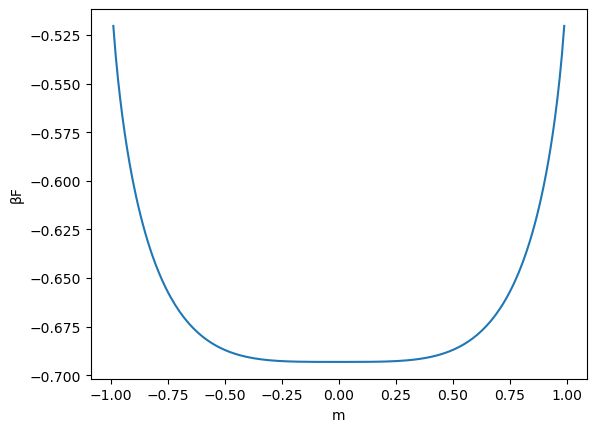

In [19]:
J = 1
C = 4
T = 4.01
beta = 1 / T
h = 0.

m = m_range
BFtilde = -beta * (0.5 * C * J * m**2 + m * h) - entropy_bernoulli(0.5 * (1 + m))

plt.plot(m, BFtilde)
plt.xlabel('m')
plt.ylabel('βF');

## Comparison with exact results

Set up a very naive fixed-point solver for the naive mean-field equation:

In [20]:
def solve_mf(m, beta, J, C, h, num_iter = 1000, tol=1e-5):
    for it in range(num_iter):
        m = np.tanh(beta * (J * C *m + h))
    return m

Solve for different values of the external field $h$ (cf. **Fig. 33.2** in McKay):

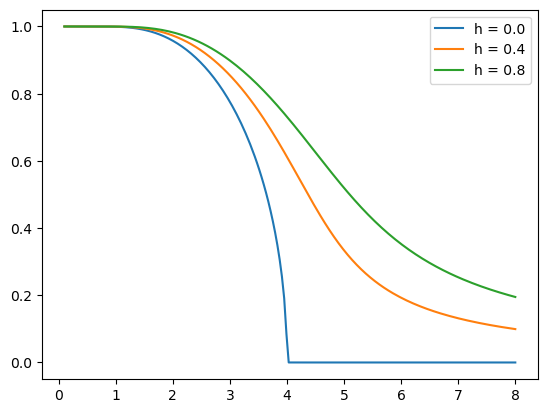

In [21]:
J = 1
C = 4
beta = 4
h = 0.4

num_T = 200
hs = [0., 0.4, 0.8]
Ts = np.linspace(0.1, 8., num_T)

ms = np.zeros((len(hs), num_T))
for ih, h in enumerate(hs):
    for iT, T in enumerate(Ts):
        beta = 1/T
        ms[ih, iT] = solve_mf(1e-1, beta, J, C, h)

for ih, h in enumerate(hs):
    plt.plot(Ts, ms[ih], label=f'h = {h}');
plt.legend();

It is a good exercise to work out all the relevant physical observables using the code for the transfer matrix method provided in **Lecture3.1**.

You will find results similar to what shown in **Fig. 33.3** in McKay:

<center><img src="figs/mean_field_ising_mckay_fig1.png", width=600></center>

The crucial failure of mean-field approximation is the absence of strong energy fluctuations at the critical point:

<center><img src="figs/mean_field_ising_mckay_fig2.png", width=300></center>

## *Bonus: MF equations and Gibbs sampling*

There exists an interesting relation between the mean field equations and the stochastic dynamics of the spin system under Gibbs sampling.

For Gibbs sampling, we sample $x_i$ from the conditional distribution $p(x_i |x_{\setminus i})$:
$$p(x_i |x_{\setminus i}) = \frac{e^{-E(x_i, x_{\setminus i})}}{\sum_{x_i'} e^{-E(x_i', x_{\setminus i})}}= \frac{e^{x_i h_i(x_{\setminus i})} }{\sum_{x_i'} e^{x_i 'h_i(x_{\setminus i}) }}=\sigma\left(x_i h_i(x_{\setminus i})\right)$$
with $h_i(x_{\setminus i})=\sum_{j\ne i}J_{ij}x_j$.

We can define a Markov process by sampling in parallel:
$$T(x'|x)=\prod_{i=1}^N \sigma\left(x_i' h_i(x_{\setminus i})\right)$$

The dynamical evolution of the distribution is $p_{t+1}(x')=\sum_x T(x'|x)p_t(x)$. The dynamics of the average is dictated by (prove it!):
$$\langle x_i \rangle_{t+1}=\sum_{x'}x_i' p_{t+1}(x')=\sum_{x,x'} x_i' T(x'|x)p_t(x)=\langle \tanh\left(h_i(x_{\setminus i})\right) \rangle_t$$

Thus, the stationary condition $p_t\to p_\infty$ is$$\langle x_i \rangle =\langle \tanh\left(h_i(x_{\setminus i})\right)\rangle\qquad h_i(x_{\setminus i})=\sum_{j\ne i}J_{ij}x_j$$
This **exact relation** really looks like the MF equations, except the average is *outside* the $\tanh$.

In a **ferromagnetic** model with $J_{ij}=\frac{J_{ij}^0}{N}$ and $J_{ij}^0>0$, the fluctuations in $h_i(x_{\setminus i})$ vanish when $N\to \infty$:

$$\langle h_i(x_{\setminus i})\rangle=\frac{1}{N}\sum_{j\ne i} J_{ij}^0\langle x_j\rangle=\mathcal{O}(1) \qquad \mathrm{Var}(h_i(x_{\setminus i}))=\frac{1}{N^2}\sum_{j\ne i} (J_{ij}^0)^2 \mathrm{Var}(x_j)=\mathcal{O}\left(\frac{1}{N}\right)$$

Thus, $h_i(x_{\setminus i})\approx \langle h_i(x_{\setminus i})\rangle$ in the large $N$ limit and the mean field equations become exact:

$$m_i =\tanh(\langle h_i(x_{\setminus i})\rangle)=\tanh\left(\sum_j J_{ij}m_j\right)$$